## Targeting Strategies
Aims to compare the effects of targeting the top 30% of customers using various strategies
1. Causal forest targeting
2. Spend-based targeting
3. Random targeting
4. Linear interaction model targeting
5. Treat everyone

### 1. Causal Forest Targeting

Run causal_forest.ipynb notebook if haven't

In [1]:
#%run causal_forest.ipynb

Imports and settings

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

RANDOM_STATE = 1213  # must match causal_forest.ipynb so the split is identical
BUDGET = 0.30  # share of customers the firm can target
N_BOOT = 500  # number of bootstrap replications

PROJECT_ROOT = Path.cwd().resolve().parent
DATA_PATH = next(p for p in [PROJECT_ROOT / "data" / "processed" / "retailhero_causal_forest_features.csv",
                             PROJECT_ROOT / "data" / "Processed" / "retailhero_causal_forest_features.csv"] if p.exists())
OUTPUT_DIR = PROJECT_ROOT / "data" / "output"
CATE_PATH = OUTPUT_DIR / "cf_cate_results.csv"

rng = np.random.default_rng(RANDOM_STATE)

Load data and rebuilt train / test set

In [2]:
df = pd.read_csv(DATA_PATH)
cate_results = pd.read_csv(CATE_PATH)

Y = df["target"].astype(int)
Z = df["treatment"].astype(int)
X = df.drop(columns=["target", "treatment", "client_id", "gender_U"], errors="ignore")

strata = Z.astype(str) + "_" + Y.astype(str)
X_train, X_test, Y_train, Y_test, Z_train, Z_test = train_test_split(
    X, Y, Z, test_size=0.3, random_state=RANDOM_STATE, stratify=strata)

# Check the rebuilt test set is the same customers, in the same order, as cf_cate_results.csv
test_ids = df.loc[X_test.index, "client_id"].to_numpy()
assert (test_ids == cate_results["client_id"].to_numpy()).all(), \
    "Test set does not match cf_cate_results.csv - rerun causal_forest.ipynb"
print(f"Test set verified: {len(test_ids):,} customers")

tau_hat = cate_results["cate_hat"].to_numpy()
y_te, z_te = Y_test.to_numpy(), Z_test.to_numpy()
n = len(y_te)

Test set verified: 60,012 customers


AIPW (Augmented Inverse Probability Weighting) score for RATE (Rank Average Treatment Effect)

In [3]:
def fit_mu(arm):
    m = RandomForestRegressor(n_estimators=100, min_samples_leaf=50,
                              random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train[Z_train == arm], Y_train[Z_train == arm])
    return m.predict(X_test)

mu1, mu0 = fit_mu(1), fit_mu(0)
e = Z_train.mean()

gamma = (mu1 - mu0
         + z_te * (y_te - mu1) / e
         - (1 - z_te) * (y_te - mu0) / (1 - e))

ate = gamma.mean()
dim = y_te[z_te == 1].mean() - y_te[z_te == 0].mean()
print(f"ATE (AIPW):               {ate:.4f}")
print(f"ATE (difference in means): {dim:.4f}   <- should be very close")

ATE (AIPW):               0.0315
ATE (difference in means): 0.0332   <- should be very close


Rank customers by CATE and select top 30%

In [4]:
def rank_order(score, rng):
    # Indices sorted from highest to lowest score, with ties broken at random
    return np.lexsort((rng.random(len(score)), -score))

k = int(round(BUDGET * n))  # number of customers you can target
order = rank_order(tau_hat, rng)

ranked = cate_results.copy()
ranked["gamma"] = gamma
ranked["cf_rank"] = np.empty(n, dtype=int)
ranked.loc[order, "cf_rank"] = np.arange(1, n + 1)
ranked["cf_top30"] = ranked["cf_rank"] <= k
ranked = ranked.sort_values("cf_rank")
display(ranked.head(10))

top = order[:k]
t, c = z_te[top] == 1, z_te[top] == 0
print(f"Customers targeted:                        {k:,}")
print(f"Uplift per targeted customer (AIPW):       {gamma[top].mean():.4f}")
print(f"Uplift per targeted customer (diff. means): {y_te[top][t].mean() - y_te[top][c].mean():.4f}")
print(f"Incremental purchases (test set):          {gamma[top].sum():.1f}")

ranked.to_csv(OUTPUT_DIR / "cf_ranked_customers.csv", index=False)

,client_id,treatment,target,cate_hat,gamma,cf_rank,cf_top30
983,205a845a5b,0,0,0.408425,0.802524,1,True
4245,5c270e445b,1,1,0.403882,1.341736,2,True
24829,f0ecaaaf57,1,1,0.401735,1.382936,3,True
34826,eb7881a604,1,1,0.398252,1.290167,4,True
7380,56b9d0d410,0,0,0.391964,0.934066,5,True
4411,ff47ffe826,1,1,0.390174,1.386189,6,True
30594,ff793eeb4b,1,0,0.379792,-0.852751,7,True
5064,55ef8029e8,1,1,0.378612,1.046007,8,True
32984,96b5100a11,0,1,0.376278,-1.231750,9,True
29584,7ec9fedd4b,1,0,0.371336,-0.855970,10,True


Customers targeted:                        18,004
Uplift per targeted customer (AIPW):       0.0586
Uplift per targeted customer (diff. means): 0.0610
Incremental purchases (test set):          1055.3


Qini curve and AUQ

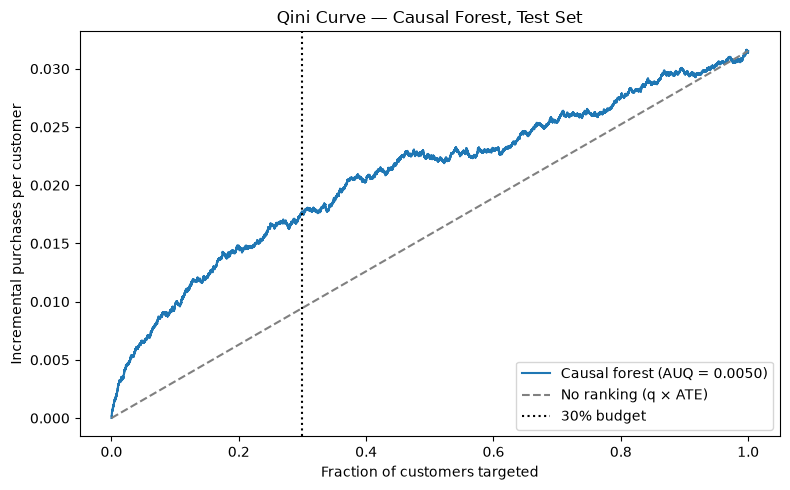

In [5]:
def qini_curve(score, gamma, rng):
    m = len(gamma)
    q = np.arange(1, m + 1) / m
    Q = np.cumsum(gamma[rank_order(score, rng)]) / m  # rng is used to break ties in the ranking
    return q, Q

def auq(score, gamma, rng):
    q, Q = qini_curve(score, gamma, rng)
    return np.mean(Q - q * gamma.mean())

def value_at(score, gamma, rng, budget=BUDGET):
    # Q(budget): incremental purchases per customer in the population at the cutoff
    m = len(gamma)
    return gamma[rank_order(score, rng)[:int(round(budget * m))]].sum() / m

q, Q = qini_curve(tau_hat, gamma, rng)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(q, Q, label=f"Causal forest (AUQ = {auq(tau_hat, gamma, rng):.4f})")
ax.plot([0, 1], [0, ate], linestyle="--", color="grey", label="No ranking (q × ATE)")
ax.axvline(BUDGET, linestyle=":", color="black", label=f"{BUDGET:.0%} budget")
ax.set_xlabel("Fraction of customers targeted")
ax.set_ylabel("Incremental purchases per customer")
ax.set_title("Qini Curve — Causal Forest, Test Set")
ax.legend()
plt.tight_layout()
plt.show()

Bootstrap for standard error and confidence intervals

In [6]:
def stats_on(idx, rng):
    g, s = gamma[idx], tau_hat[idx]
    return {
        "ATE": g.mean(),
        "AUQ (Qini coefficient)": auq(s, g, rng),
        "Q(30%)": value_at(s, g, rng),
        "Uplift per targeted customer": value_at(s, g, rng) / BUDGET,
    }

point = stats_on(np.arange(n), rng)
boot = pd.DataFrame([stats_on(rng.integers(0, n, n), rng) for _ in range(N_BOOT)])

results = pd.DataFrame({
    "estimate": pd.Series(point),
    "boot_se": boot.std(ddof=1),
    "ci_lower": boot.quantile(0.025),
    "ci_upper": boot.quantile(0.975),
})
results["z"] = results["estimate"] / results["boot_se"]
display(results.round(4))

results.to_csv(OUTPUT_DIR / "cf_targeting_results.csv")
print(f"Saved to {OUTPUT_DIR / 'cf_targeting_results.csv'}")

,estimate,boot_se,ci_lower,ci_upper,z
ATE,0.0315,0.0034,0.0254,0.0383,9.1988
AUQ (Qini coefficient),0.0050,0.0010,0.0030,0.0069,4.9085
Q(30%),0.0176,0.0020,0.0137,0.0214,8.8514
Uplift per targeted customer,0.0586,0.0066,0.0455,0.0712,8.8514


Saved to C:\Users\hai liang\DSE4101-CausalForest-Grp2\data\output\cf_targeting_results.csv


### 2-3 Spending-based targetting (top and bottom 30% in spending) and random targeting

Spending-based targeting: top and bottom 30%

In [7]:
assert "total_spend" in X_test.columns, "Expected pre-treatment total_spend in X_test"
spend = X_test["total_spend"].to_numpy(dtype=float)
assert np.isfinite(spend).all(), "Missing/nonfinite total_spend values"
#make sure highest/lowest is first
spend_scores = {
    "Top 30% spend": spend,
    "Bottom 30% spend": -spend,#- to reverse the order
}
spend_orders = {
    name: rank_order(score, np.random.default_rng(RANDOM_STATE + 201 + i))
    for i, (name, score) in enumerate(spend_scores.items())
}

spend_rows = []
for name, idx_order in spend_orders.items():
    selected = idx_order[:k]
    spend_rows.append({
        "strategy": name,
        "n_targeted": len(selected),
        "share_targeted": len(selected) / n,
        "Q(30%)": gamma[selected].sum() / n,
        "uplift_per_targeted": gamma[selected].mean(),
        "incremental_purchases_test": gamma[selected].sum(),
    })

spend_table = pd.DataFrame(spend_rows).set_index("strategy")
display(spend_table.round(4))

,n_targeted,share_targeted,Q(30%),uplift_per_targeted,incremental_purchases_test
strategy,,,,,
Top 30% spend,18004,0.3,0.0034,0.0113,203.0507
Bottom 30% spend,18004,0.3,0.0154,0.0513,922.9771


Random targeting: 30% of customers

In [8]:
random_score = rng.random(n)
random_order = rank_order(random_score, rng)
random_selected = random_order[:k]

random_table = pd.DataFrame([{
    "strategy": "Random 30%",
    "n_targeted": len(random_selected),
    "share_targeted": len(random_selected) / n,
    "Q(30%)": gamma[random_selected].sum() / n,
    "uplift_per_targeted": gamma[random_selected].mean(),
    "incremental_purchases_test": gamma[random_selected].sum(),
}]).set_index("strategy")

display(random_table.round(4))

,n_targeted,share_targeted,Q(30%),uplift_per_targeted,incremental_purchases_test
strategy,,,,,
Random 30%,18004,0.3,0.0117,0.0389,699.9871


Comparing all 30% targeting strategies

In [9]:
policy_scores = {
    "CF top 30%": tau_hat,
    **spend_scores,
    "Random 30%": random_score,
}

orders = {
    "CF top 30%": rank_order(tau_hat, rng),
    **spend_orders,
    "Random 30%": random_order,
}
policy_table = pd.concat([
    pd.DataFrame([{
        "strategy": "CF top 30%",
        "n_targeted": k,
        "share_targeted": k / n,
        "Q(30%)": gamma[orders["CF top 30%"][:k]].sum() / n,
        "uplift_per_targeted": gamma[orders["CF top 30%"][:k]].mean(),
        "incremental_purchases_test": gamma[orders["CF top 30%"][:k]].sum(),
    }]).set_index("strategy"),
    spend_table,
    random_table,
])
display(policy_table.round(4))

,n_targeted,share_targeted,Q(30%),uplift_per_targeted,incremental_purchases_test
strategy,,,,,
CF top 30%,18004,0.3,0.0176,0.0586,1055.3157
Top 30% spend,18004,0.3,0.0034,0.0113,203.0507
Bottom 30% spend,18004,0.3,0.0154,0.0513,922.9771
Random 30%,18004,0.3,0.0117,0.0389,699.9871


Bootstrap

In [11]:

rng_boot = np.random.default_rng(RANDOM_STATE)

assert len(tau_hat) == len(gamma) == len(spend) == n

# Fixed random scores for random targeting
random_scores = rng_boot.random(n)

def stats_cf_vs_strategy(idx, rng):
    g = gamma[idx]
    cf = tau_hat[idx]

    strategies = {
        "Top 30% spend": spend[idx],
        "Bottom 30% spend": -spend[idx],
        "Random 30%": random_scores[idx]
    }

    results = {}

    for name, s in strategies.items():
        cf_q30 = value_at(cf, g, rng)
        s_q30 = value_at(s, g, rng)

        results[f"Q(30%) difference (CF - {name})"] = cf_q30 - s_q30

        results[f"AUQ difference (CF - {name})"] = (
            auq(cf, g, rng) - auq(s, g, rng)
        )

        results[f"Uplift per targeted customer difference (CF - {name})"] = (
            cf_q30 - s_q30
        ) / BUDGET

    return results


# Point estimates
point = stats_cf_vs_strategy(np.arange(n), rng_boot)

# Paired bootstrap
boot = pd.DataFrame([
    stats_cf_vs_strategy(rng_boot.integers(0, n, n), rng_boot)
    for _ in range(N_BOOT)
])

# Results table
results_strategy_comparison = pd.DataFrame({
    "estimate": pd.Series(point),
    "boot_se": boot.std(ddof=1),
    "ci_lower": boot.quantile(0.025),
    "ci_upper": boot.quantile(0.975),
})

results_strategy_comparison["z"] = (
    results_strategy_comparison["estimate"] /
    results_strategy_comparison["boot_se"]
)

display(results_strategy_comparison.round(4))


,estimate,boot_se,ci_lower,ci_upper,z
Q(30%) difference (CF - Top 30% spend),0.0142,0.0025,0.0094,0.0190,5.7955
AUQ difference (CF - Top 30% spend),0.0099,0.0016,0.0068,0.0131,6.1242
Uplift per targeted customer difference (CF - Top 30% spend),0.0473,0.0082,0.0312,0.0632,5.7955
Q(30%) difference (CF - Bottom 30% spend),0.0022,0.0020,-0.0015,0.0063,1.1007
AUQ difference (CF - Bottom 30% spend),0.0001,0.0010,-0.0019,0.0021,0.0996
Uplift per targeted customer difference (CF - Bottom 30% spend),0.0074,0.0067,-0.0051,0.0208,1.1007
Q(30%) difference (CF - Random 30%),0.0085,0.0023,0.0041,0.0130,3.7390
AUQ difference (CF - Random 30%),0.0059,0.0014,0.0034,0.0088,4.1884
Uplift per targeted customer difference (CF - Random 30%),0.0285,0.0076,0.0136,0.0433,3.7390


### 4. Linear Interaction Model Targeting

In [12]:
# Choosing the covariates
moderators = [
    "age",
    "total_spend",
    "num_transactions",
    "days_since_last_purchase",
    "customer_activity_span"
]

# Checking correlation
corr = X_train[moderators].corr()
display(corr.round(2))

,age,total_spend,num_transactions,days_since_last_purchase,customer_activity_span
age,1.00,-0.03,0.04,-0.04,0.10
total_spend,-0.03,1.00,0.58,-0.29,0.35
num_transactions,0.04,0.58,1.00,-0.41,0.45
days_since_last_purchase,-0.04,-0.29,-0.41,1.00,-0.34
customer_activity_span,0.10,0.35,0.45,-0.34,1.00


Standardising moderators

In [13]:
scaler = StandardScaler()

X_train_lpm = X_train[moderators].copy()
X_test_lpm = X_test[moderators].copy()

X_train_lpm[moderators] = scaler.fit_transform(X_train_lpm[moderators])
X_test_lpm[moderators] = scaler.transform(X_test_lpm[moderators])

Model Equation:

$$
\begin{aligned}
Y_i =\;& \beta_0 + \beta_D D_i
+ \beta_1 Age_i
+ \beta_2 Spend_i
+ \beta_3 Transactions_i \\
&+ \beta_4 Recency_i
+ \beta_5 ActivitySpan_i \\
&+ \gamma_1(D_i \times Age_i)
+ \gamma_2(D_i \times Spend_i) \\
&+ \gamma_3(D_i \times Transactions_i)
+ \gamma_4(D_i \times Recency_i) \\
&+ \gamma_5(D_i \times ActivitySpan_i)
+ \varepsilon_i
\end{aligned}
$$

In [14]:
train_lpm = X_train_lpm.copy()
train_lpm["treatment"] = Z_train.to_numpy()
train_lpm["target"] = Y_train.to_numpy()

formula = (
    "target ~ treatment * ("
    "age + total_spend + num_transactions + "
    "days_since_last_purchase + customer_activity_span)"
)

lpm = smf.ols(formula, data=train_lpm).fit(cov_type="HC3")

print(lpm.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.171
Model:                            OLS   Adj. R-squared:                  0.170
Method:                 Least Squares   F-statistic:                     2932.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:52:08   Log-Likelihood:                -84395.
No. Observations:              140027   AIC:                         1.688e+05
Df Residuals:                  140015   BIC:                         1.689e+05
Df Model:                          11                                         
Covariance Type:                  HC3                                         
                                         coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Inte

Predict test-set CATEs

In [15]:
test_treated = X_test_lpm.copy()
test_treated["treatment"] = 1

test_control = X_test_lpm.copy()
test_control["treatment"] = 0

cate_lpm = (lpm.predict(test_treated)- lpm.predict(test_control)).to_numpy()

print("Number of predictions:", len(cate_lpm))
print("Minimum CATE:", cate_lpm.min())
print("Maximum CATE:", cate_lpm.max())
print("Average CATE:", cate_lpm.mean())

Number of predictions: 60012
Minimum CATE: -0.14123260465760445
Maximum CATE: 0.08139219551436216
Average CATE: 0.031881366165975596


Rank customers by CATE and select the top 30%

In [16]:
order_lpm = rank_order(cate_lpm, np.random.default_rng(RANDOM_STATE))
top_lpm = order_lpm[:k]

print("Customers targeted:", len(top_lpm))

Customers targeted: 18004


Evaluate incremental purchases

In [17]:
uplift_lpm = gamma[top_lpm].mean()
incremental_lpm = gamma[top_lpm].sum()

print(f"LPM uplift per targeted customer: {uplift_lpm:.4f}")
print(f"LPM incremental purchases: {incremental_lpm:.1f}")

LPM uplift per targeted customer: 0.0621
LPM incremental purchases: 1117.2


Qini and AUQ

In [18]:
q_lpm, Q_lpm = qini_curve(
    cate_lpm, gamma, np.random.default_rng(RANDOM_STATE)
)

auq_lpm = auq(
    cate_lpm, gamma, np.random.default_rng(RANDOM_STATE)
)

print(f"LPM AUQ: {auq_lpm:.4f}")

LPM AUQ: 0.0060


Bootstrap

In [19]:
rng_boot = np.random.default_rng(RANDOM_STATE)

# Check that arrays are aligned
assert len(cate_lpm) == len(tau_hat) == len(gamma) == n

def stats_cf_vs_lpm(idx, rng):
    g = gamma[idx]
    cf = tau_hat[idx]
    lp = cate_lpm[idx]

    return {
        "AUQ difference (CF - LPM)": auq(cf, g, rng) - auq(lp, g, rng),
        "Q(30%) difference (CF - LPM)": value_at(cf, g, rng) - value_at(lp, g, rng),
        "Uplift per targeted customer difference": (
            value_at(cf, g, rng) - value_at(lp, g, rng)
        ) / BUDGET
    }

# Point estimates
point = stats_cf_vs_lpm(np.arange(n), rng_boot)

# Bootstrap
boot = pd.DataFrame([
    stats_cf_vs_lpm(rng_boot.integers(0, n, n), rng_boot)
    for _ in range(N_BOOT)
])

# Results table
results_lpm_comparison = pd.DataFrame({
    "estimate": pd.Series(point),
    "boot_se": boot.std(ddof=1),
    "ci_lower": boot.quantile(0.025),
    "ci_upper": boot.quantile(0.975),
})

results_lpm_comparison["z"] = (
    results_lpm_comparison["estimate"] /
    results_lpm_comparison["boot_se"]
)

display(results_lpm_comparison.round(4))

# Save results
results_lpm_comparison.to_csv(
    OUTPUT_DIR / "cf_vs_lpm_targeting_results.csv"
)
print(f"Saved to {OUTPUT_DIR / 'cf_vs_lpm_targeting_results.csv'}")

,estimate,boot_se,ci_lower,ci_upper,z
AUQ difference (CF - LPM),-0.0009,0.0012,-0.0031,0.0012,-0.8069
Q(30%) difference (CF - LPM),-0.0010,0.0021,-0.0048,0.0031,-0.5016
Uplift per targeted customer difference,-0.0034,0.0069,-0.0162,0.0103,-0.5016


Saved to /Users/shannonkwok/Desktop/DSE4101/DSE4101-CausalForest-Grp2/data/output/cf_vs_lpm_targeting_results.csv


### 5. Treating Everyone

In [20]:
everyone_summary = pd.Series({
    "Customers targeted": n,
    "Uplift per targeted customer (AIPW)": gamma.mean(),
    "Uplift per targeted customer (diff. means)": y_te[z_te == 1].mean() - y_te[z_te == 0].mean(),
    "Incremental purchases (test set)": gamma.sum(),
})
display(everyone_summary.round(4))

Customers targeted                            60012.0000
Uplift per targeted customer (AIPW)               0.0315
Uplift per targeted customer (diff. means)        0.0332
Incremental purchases (test set)               1891.8914
dtype: float64

Bootstrap

In [21]:
def stats_everyone(idx, rng):
    g, s = gamma[idx], tau_hat[idx]
    ate_b = g.mean()
    q30 = value_at(s, g, rng)
    return {
        "Everyone: uplift per targeted customer (= ATE)": ate_b,
        "Everyone: Q(100%)": ate_b,
        "CF: uplift per targeted customer": q30 / BUDGET,
        "Uplift per targeted: CF - everyone": q30 / BUDGET - ate_b,
        "Share of total uplift captured by CF top 30%": q30 / ate_b,
    }

point_ev = stats_everyone(np.arange(n), rng)
boot_ev = pd.DataFrame([stats_everyone(rng.integers(0, n, n), rng) for _ in range(N_BOOT)])

results_everyone = pd.DataFrame({
    "estimate": pd.Series(point_ev),
    "boot_se": boot_ev.std(ddof=1),
    "ci_lower": boot_ev.quantile(0.025),
    "ci_upper": boot_ev.quantile(0.975),
})
results_everyone["z"] = results_everyone["estimate"] / results_everyone["boot_se"]
display(results_everyone.round(4))

results_everyone.to_csv(OUTPUT_DIR / "everyone_targeting_results.csv")
print(f"Saved to {OUTPUT_DIR / 'everyone_targeting_results.csv'}")

,estimate,boot_se,ci_lower,ci_upper,z
Everyone: uplift per targeted customer (= ATE),0.0315,0.0035,0.0248,0.0385,9.0738
Everyone: Q(100%),0.0315,0.0035,0.0248,0.0385,9.0738
CF: uplift per targeted customer,0.0586,0.0070,0.0452,0.0716,8.3713
Uplift per targeted: CF - everyone,0.0271,0.0056,0.0157,0.0377,4.8064
Share of total uplift captured by CF top 30%,0.5578,0.0581,0.4527,0.6803,9.5933


Saved to /Users/shannonkwok/Desktop/DSE4101/DSE4101-CausalForest-Grp2/data/output/everyone_targeting_results.csv


Combined QINI


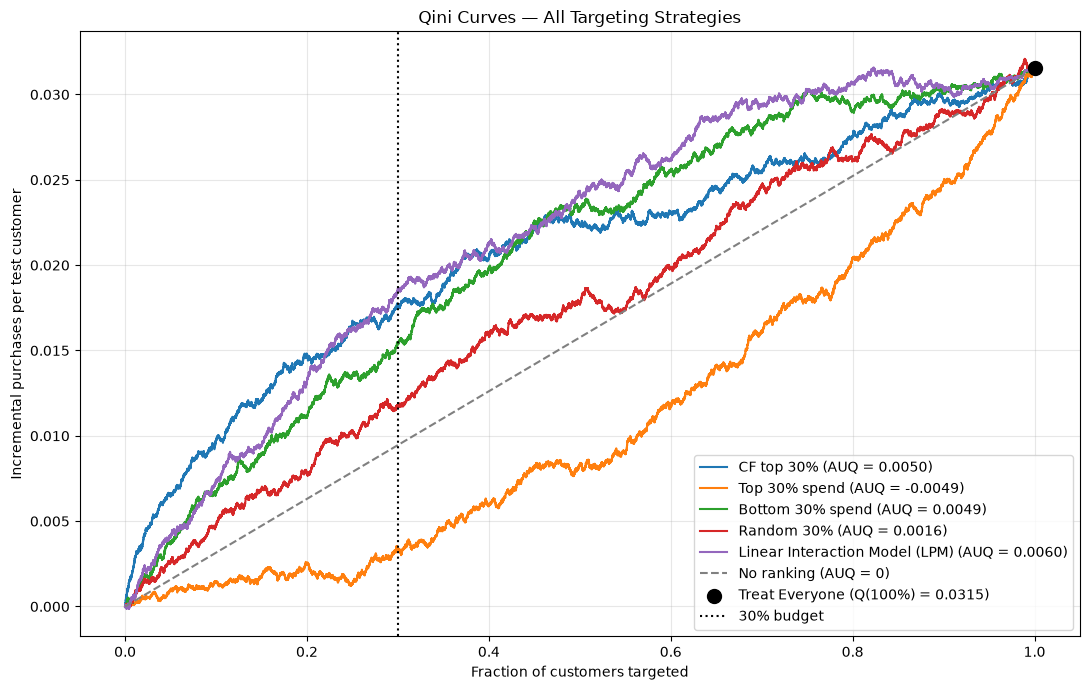

,AUQ,Q(30%),Q(100%)
Strategy,,,
CF top 30%,0.00502,0.01759,0.03153
Top 30% spend,-0.00492,0.00338,0.03153
Bottom 30% spend,0.00492,0.01538,0.03153
Random 30%,0.00158,0.01166,0.03153
Linear Interaction Model (LPM),0.00595,0.01862,0.03153
Treat Everyone,0.00000,NaN,0.03153


In [22]:
#combined Qini Curves and AUQ 

all_orders = {
    **orders,
    "Linear Interaction Model (LPM)": rank_order(
        cate_lpm, np.random.default_rng(RANDOM_STATE)
    )
}

q = np.arange(1, n + 1) / n
ate = gamma.mean()

fig, ax = plt.subplots(figsize=(11, 7))

qini_rows = []

#plot all ranking - based 
for name, idx_order in all_orders.items():

    Q = np.cumsum(gamma[idx_order]) / n
    auq_est = np.mean(Q - q * ate)
    q30 = gamma[idx_order[:k]].sum() / n

    qini_rows.append({
        "Strategy": name,
        "AUQ": auq_est,
        "Q(30%)": q30,
        "Q(100%)": ate
    })

    ax.plot(
        q, Q,
        label=f"{name} (AUQ = {auq_est:.4f})"
    )

#baseline
ax.plot(
    [0, 1], [0, ate],
    "--", color="grey",
    label="No ranking (AUQ = 0)"
)

#treat everyone
ax.scatter(
    1, ate,
    color="black",
    marker="o",
    s=100,
    zorder=5,
    label=f"Treat Everyone (Q(100%) = {ate:.4f})"
)


qini_rows.append({
    "Strategy": "Treat Everyone",
    "AUQ": 0.0,
    "Q(30%)": np.nan,
    "Q(100%)": ate
})

#30% budget
ax.axvline(
    BUDGET,
    linestyle=":",
    color="black",
    label="30% budget"
)

ax.set_xlabel("Fraction of customers targeted")
ax.set_ylabel("Incremental purchases per test customer")
ax.set_title("Qini Curves — All Targeting Strategies")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#comparison table
qini_comparison = pd.DataFrame(qini_rows)

display(
    qini_comparison.set_index("Strategy").round(5)
)